<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/7%EC%A3%BC%EC%B0%A8/10_26_mobile_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# 1. 라이브러리 & 데이터 불러오기

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/mobile.csv")



In [9]:
# 2. EDA
# 결측치, 중복
print(df.isnull().sum().sum(), "개 결측치")
print(df.duplicated().sum(), "개 중복")

# 정답 분포
print(df["price_range"].value_counts().sort_index())

# 이상치 / 말이 안 되는 값
print(df.describe().T)
print("px_height == 0:", (df["px_height"] == 0).sum())
print("sc_w == 0:", (df["sc_w"] == 0).sum())

# 정답과 상관이 큰 특성
print(df.corr()["price_range"].sort_values(ascending=False))

0 개 결측치
0 개 중복
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64
                count        mean          std    min      25%     50%  \
battery_power  2000.0  1238.51850   439.418206  501.0   851.75  1226.0   
blue           2000.0     0.49500     0.500100    0.0     0.00     0.0   
clock_speed    2000.0     1.52225     0.816004    0.5     0.70     1.5   
dual_sim       2000.0     0.50950     0.500035    0.0     0.00     1.0   
fc             2000.0     4.30950     4.341444    0.0     1.00     3.0   
four_g         2000.0     0.52150     0.499662    0.0     0.00     1.0   
int_memory     2000.0    32.04650    18.145715    2.0    16.00    32.0   
m_dep          2000.0     0.50175     0.288416    0.1     0.20     0.5   
mobile_wt      2000.0   140.24900    35.399655   80.0   109.00   141.0   
n_cores        2000.0     4.52050     2.287837    1.0     3.00     4.0   
pc             2000.0     9.91650     6.064315    0.0     5.00    10.0   
px_height      2000.0  

In [11]:
# 3. 전처리
## 결측치 / 중복 : 없음
## 이상치 제거 :
### px_height (화면 세로 픽셀) == 0 인 값 제거
### sc_w (화면 너비) == 0 인 값은 노이즈 지만 전체의 9% 여서 제거하기엔 많지만 price_range와 상관이 낮은 특성이므로 중앙값으로 대체

df = df[df["px_height"] > 0].reset_index(drop=True)

sc_w_median = df.loc[df["sc_w"] > 0, "sc_w"].median()
df.loc[df["sc_w"] == 0, "sc_w"] = sc_w_median


In [12]:
# 4. 학습 / 테스트 분할
X = df.drop(columns=["price_range"]).values.astype("float32")

Y_df = pd.get_dummies(df["price_range"])
labels = Y_df.columns.tolist()
Y = Y_df.values.astype("float32")
print("클래스 순서:", labels, "| X 모양:", X.shape, "| Y 모양:", Y.shape)

클래스 순서: [0, 1, 2, 3] | X 모양: (1998, 20) | Y 모양: (1998, 4)


In [13]:
# 5. 학습 / 테스트 분할 + 스케일링

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, stratify=df["price_range"], random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # train으로만 fit
X_test = scaler.transform(X_test)

In [14]:
# 6. 모델 구성
# 다중 분류 + 단일 레이블 → 출력층 softmax, 클래스가 4개라 노드 4개
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(4, activation="softmax"),
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,556 (13.89 KB)

 Trainable params: 3,556 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# 7. 학습
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

## train 데이터 에서 20% 를 validation 데이터셋으로 쓴다
## 이 validation 데이터셋으로 val_accuracy 와 val_loss 를 구하는 것이다
history = model.fit(
    X_train, y_train,
    epochs=200, batch_size=32,
    validation_split=0.2, callbacks=[early], verbose=1)

Epoch 1/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2958 - loss: 1.4033 - val_accuracy: 0.3469 - val_loss: 1.3286
Epoch 2/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4507 - loss: 1.1775 - val_accuracy: 0.4844 - val_loss: 1.1429
Epoch 3/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6338 - loss: 0.9373 - val_accuracy: 0.6000 - val_loss: 0.9297
Epoch 4/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7363 - loss: 0.7340 - val_accuracy: 0.7063 - val_loss: 0.7547
Epoch 5/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8161 - loss: 0.5857 - val_accuracy: 0.7656 - val_loss: 0.6223
Epoch 6/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8623 - loss: 0.4762 - val_accuracy: 0.8156 - val_loss: 0.5250
Epoch 7/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9077 - loss: 0.3945 - val_accuracy: 0.8344 - val_loss: 0.4540
Epoch 8/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9272 - loss: 0.3319 - val_accuracy: 0.8531 - v

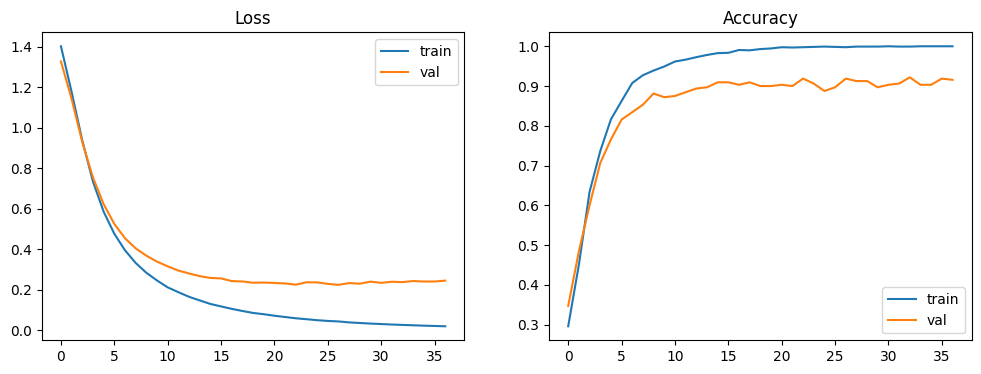

In [17]:
# 8. 학습 곡선 (과적합 여부 확인)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Accuracy: 0.9225
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       100
           1       0.93      0.89      0.91       100
           2       0.89      0.90      0.90       100
           3       0.93      0.94      0.94       100

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



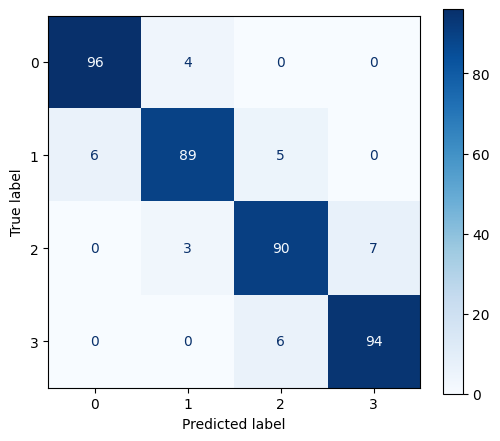

In [19]:
# 9. 평가: 확률 → 클래스 번호, 원-핫 정답 → 클래스 번호
y_pred = np.argmax(model.predict(X_test), axis=1)   # 예측 클래스 번호
y_true = np.argmax(y_test, axis=1)                  # 정답 클래스 번호

all_classes = range(len(labels))
label_names = [str(l) for l in labels]

print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, labels=all_classes,
                            target_names=label_names, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=all_classes),
                       display_labels=label_names).plot(cmap="Blues", ax=ax, values_format="d")
plt.show()

In [ ]:
# 10. 결과 분석
## 높은 정확도가 나옴 (0.925)
## 하지만 위에서 구한 학습 곡선에서 train accuracy 1.0, val accuracy 약 0.91로 차이가 벌어지고
## val loss가 정체 후 증가한 것으로 보아 과적합이 발생했다고 생각

## 그래도 정확도가 높은 이유는 EarlyStopping을 통해서 patience : 10으로 설정했기 때문에
## val_loss가 가장 낮았던 에폭 이후 10 에폭 동안 그보다 낮아지지 않으면 학습을 멈추고 가장 낮았던 시점의 가중치로 되돌아간다
## 그래서 과적합은 학습을 오래 할 수록 학습 데이터의 노이즈 까지 학습하기 때문에 과적합이 심해진다
## 그래서 기존보다 val_loss 가 커진다는거는 얘가 train 데이터셋을 너무 과적합 해서 validation 데이터셋으로 검증 했을 때
## 손실이 커진 거니까 EarlyStopping으로 빨리 종료를 시킴으로써 더이상 모델이 과적합 되지 않도록 막는다



In [ ]:
# 11. 과적합이 발생한 이유

## 1. 데이터셋에 비해 모델이 너무 크다
모델의 전체 파라미터가 3556개 인데 학습용 데이터 셋이 1278 여서 과적합이 발생 할 수 있다

##2. 쓸모없는 특성이 대부분이다
EDA의 상관관계를 보면 ram 이 0.92로 엄청 크게 나왔지만 그에 비해 그나마
battery_power, px_width, px_height 는 약한 관계를 띄지만 나머지 16개는 관계가 거의 없는 수준임
그래서 사실상 이 특성들은 노이즈나 다름 없음



In [21]:
# 12. 과적합 해결해보기

# 중요한 특성만 사용
top_cols = ["ram", "battery_power", "px_height", "px_width"]
X_top = df[top_cols].values.astype("float32")

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_top, Y, test_size=0.2, stratify=df["price_range"], random_state=42)
sc = StandardScaler()
Xt_train = sc.fit_transform(Xt_train)
Xt_test = sc.transform(Xt_test)

model_top = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(Xt_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(4, activation="softmax"),
])
model_top.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                         min_delta=0.001, restore_best_weights=True)
h_top = model_top.fit(Xt_train, yt_train, epochs=200, batch_size=32,
                      validation_split=0.2, callbacks=[early], verbose=0)


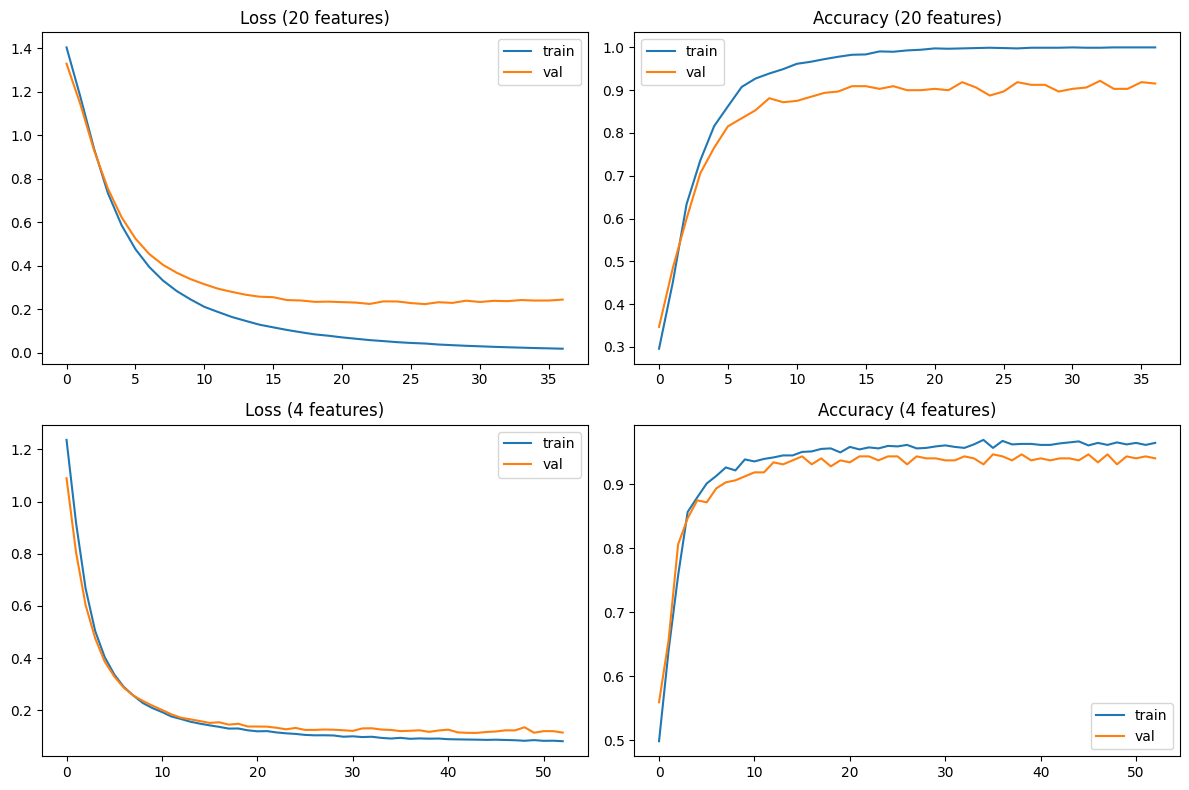

========20개 특성 vs 4개 특성 ( train , test 데이터 정확도 비교 )========
20개 특성 train / test: 0.98310387134552 0.9225000143051147
4개 특성 train / test: 0.9637046456336975 0.9649999737739563


In [30]:
# 13. 학습 곡선 비교
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (h, name) in enumerate([(history, "20 features"), (h_top, "4 features")]):
    axes[row, 0].plot(h.history["loss"], label="train")
    axes[row, 0].plot(h.history["val_loss"], label="val")
    axes[row, 0].set_title(f"Loss ({name})"); axes[row, 0].legend()

    axes[row, 1].plot(h.history["accuracy"], label="train")
    axes[row, 1].plot(h.history["val_accuracy"], label="val")
    axes[row, 1].set_title(f"Accuracy ({name})"); axes[row, 1].legend()

plt.tight_layout()
plt.show()

print("========20개 특성 vs 4개 특성 ( train , test 데이터 정확도 비교 )========")
print("20개 특성 train / test:",
      model.evaluate(X_train, y_train, verbose=0)[1], model.evaluate(X_test, y_test, verbose=0)[1])
print("4개 특성 train / test:",
      model_top.evaluate(Xt_train, yt_train, verbose=0)[1], model_top.evaluate(Xt_test, yt_test, verbose=0)[1])

In [ ]:
# 14. 결론
학습 곡선을 보면 위쪽 2개의 그래프는 20개의 특성을 모두 사용했을 때 이고 아래 2개는 유의미한 상관관계를 띈 4개의 특성만
골랐을 때이다
두 그래프를 비교해보니 특성을 줄이니 train과 val의 차이가 사라졌다 라는 것을 알 수 있고 train과 test 정확도 차이가
거의 없어졌음을 알 수 있다. 위에 20개 특성을 모두 살렸을 때는 train 데이터셋에는 정확도가 높지만 그에 비해 test에서
정확도가 떨어짐을 알 수 있었는데 4개의 특성으로 줄이니 정확도 차이가 거의 없어짐을 알 수 있다